In [1]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
from src.config import calibrations_path,vendor_path,figures_path
from lmfit.models import Gaussian2dModel
import pandas as pd
%load_ext autoreload
%autoreload 2

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [91]:
file_name = 'spots_iwp_u_27apr'
img = np.load(f"{figures_path/'raw'/file_name}.npy")

In [92]:
centrex = 1180
centrey = 230
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)]).T

In [93]:
results = []
for spot_location in spot_locations.T:
    target = img[spot_location[1]-30:spot_location[1]+70,spot_location[0]-40:spot_location[0]+60]
    # plt.imshow(target)
    xdata = np.array([[i,j] for i in range(target.shape[0]) for j in range(target.shape[1])]).T
    model = Gaussian2dModel()
    params = model.guess(target.ravel(),xdata[0].ravel(),xdata[1].ravel())
    result = model.fit(target.ravel(),params,x = xdata[0].ravel(),y = xdata[1].ravel(),max_nfev = 10000)
    out_dict = result.params.valuesdict()
    out_dict['rsquared'] = result.rsquared
    results.append(out_dict)

In [94]:
pdf = pd.DataFrame(results)

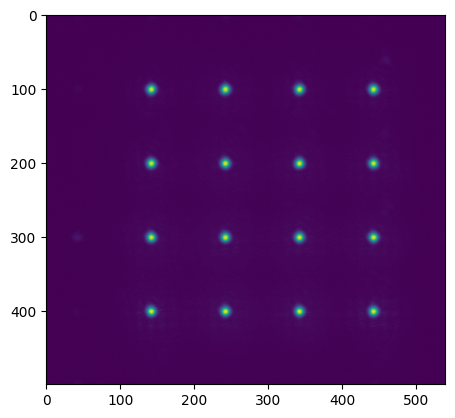

In [95]:
plt.imshow(img[100:600,900:])

In [96]:
pdf

,amplitude,centerx,centery,sigmax,sigmay,fwhmx,fwhmy,height,rsquared
0,47358.285846,51.336328,51.777331,4.464638,4.321829,10.513420,10.177129,390.626871,0.980035
1,47382.296191,51.303060,51.766994,4.470434,4.332834,10.527067,10.203045,389.326854,0.971871
2,47233.961809,51.308865,51.802865,4.470315,4.343870,10.526787,10.229032,387.132348,0.955588
3,47486.652267,51.318593,51.781287,4.437942,4.352254,10.450554,10.248774,391.287288,0.947823
4,47575.681898,51.332274,51.745878,4.482373,4.312862,10.555181,10.156013,391.680155,0.974632
5,47657.462622,51.333821,51.792093,4.458947,4.342894,10.500018,10.226733,391.687216,0.961504
6,47378.096732,51.329166,51.788309,4.467271,4.318753,10.519619,10.169887,390.838129,0.945358
7,47607.419795,51.330955,51.809911,4.431759,4.348401,10.435995,10.239702,393.177728,0.937814
8,47534.666145,51.333159,51.755907,4.482417,4.337276,10.555285,10.213504,389.135758,0.975762
9,47484.463988,51.334178,51.778843,4.476026,4.312467,10.540236,10.155083,391.519289,0.959643


C:\Users\QC\AppData\Local\Temp\ipykernel_7476\1621724113.py:40: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout(rect=[1, 0, 1, 0.9])


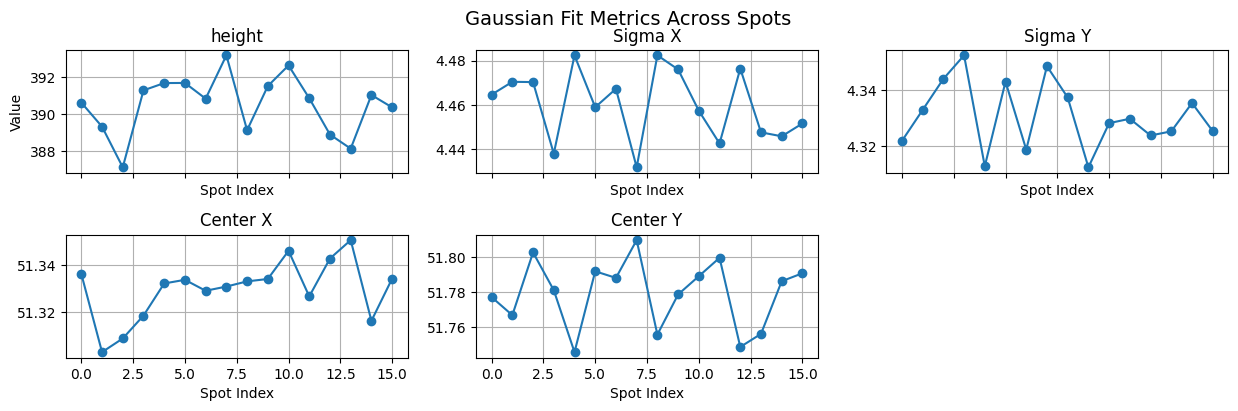

In [135]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(15, 4), sharex=True)
axs = axs.flatten()
# Plot amplitudes
axs[0].plot(pdf.index, pdf['height'], marker='o')
axs[0].set_title("height")
axs[0].set_xlabel("Spot Index")
axs[0].set_ylabel("Value")
axs[0].grid(True)

# Plot sigmax
axs[1].plot(pdf.index, pdf['sigmax'], marker='o')
axs[1].set_title("Sigma X")
axs[1].set_xlabel("Spot Index")
axs[1].grid(True)

# Plot sigmay
axs[2].plot(pdf.index, pdf['sigmay'], marker='o')
axs[2].set_title("Sigma Y")
axs[2].set_xlabel("Spot Index")
axs[2].grid(True)


# Plot centerx
axs[3].plot(pdf.index, pdf['centerx'], marker='o')
axs[3].set_title("Center X")
axs[3].set_xlabel("Spot Index")
axs[3].grid(True)


# Plot centery
axs[4].plot(pdf.index, pdf['centery'], marker='o')
axs[4].set_title("Center Y")
axs[4].set_xlabel("Spot Index")
axs[4].grid(True)

fig.delaxes(axs[5])
plt.suptitle("Gaussian Fit Metrics Across Spots", fontsize=14)
plt.tight_layout(rect=[1, 0, 1, 0.9])
plt.subplots_adjust(hspace=0.5) 
plt.show()


In [98]:
std_percent = (pdf.std() / pdf.mean()) * 100
selected = std_percent[['height','sigmax','sigmay','centerx','centery']]
styled = selected.to_frame(name='Std Dev (%)').style.set_caption("Standard Deviation as % of Mean").format(precision=2)
styled

,Std Dev (%)
height,0.42
sigmax,0.36
sigmay,0.28
centerx,0.02
centery,0.04


In [104]:
def uniformity_metric(series):
    return (series.max() - series.min()) / (series.max() + series.min())

u_height = uniformity_metric(pdf['height'])
u_sigmax = uniformity_metric(pdf['sigmax'])
u_sigmay = uniformity_metric(pdf['sigmay'])
u_centerx = uniformity_metric(pdf['centerx'])
u_centery = uniformity_metric(pdf['centery'])

print(f"Uniformity Metrics:")
print(f"  Height  : {u_height*100:.2f}%")
print(f"  Sigma X : {u_sigmax*100:.2f}%")
print(f"  Sigma Y : {u_sigmay*100:.2f}%")
print(f"  Center X : {u_centerx*100:.2f}%")
print(f"  Center Y : {u_centery*100:.2f}%")

Uniformity Metrics:
  Height  : 0.77%
  Sigma X : 0.57%
  Sigma Y : 0.46%
  Center X : 0.05%
  Center Y : 0.06%


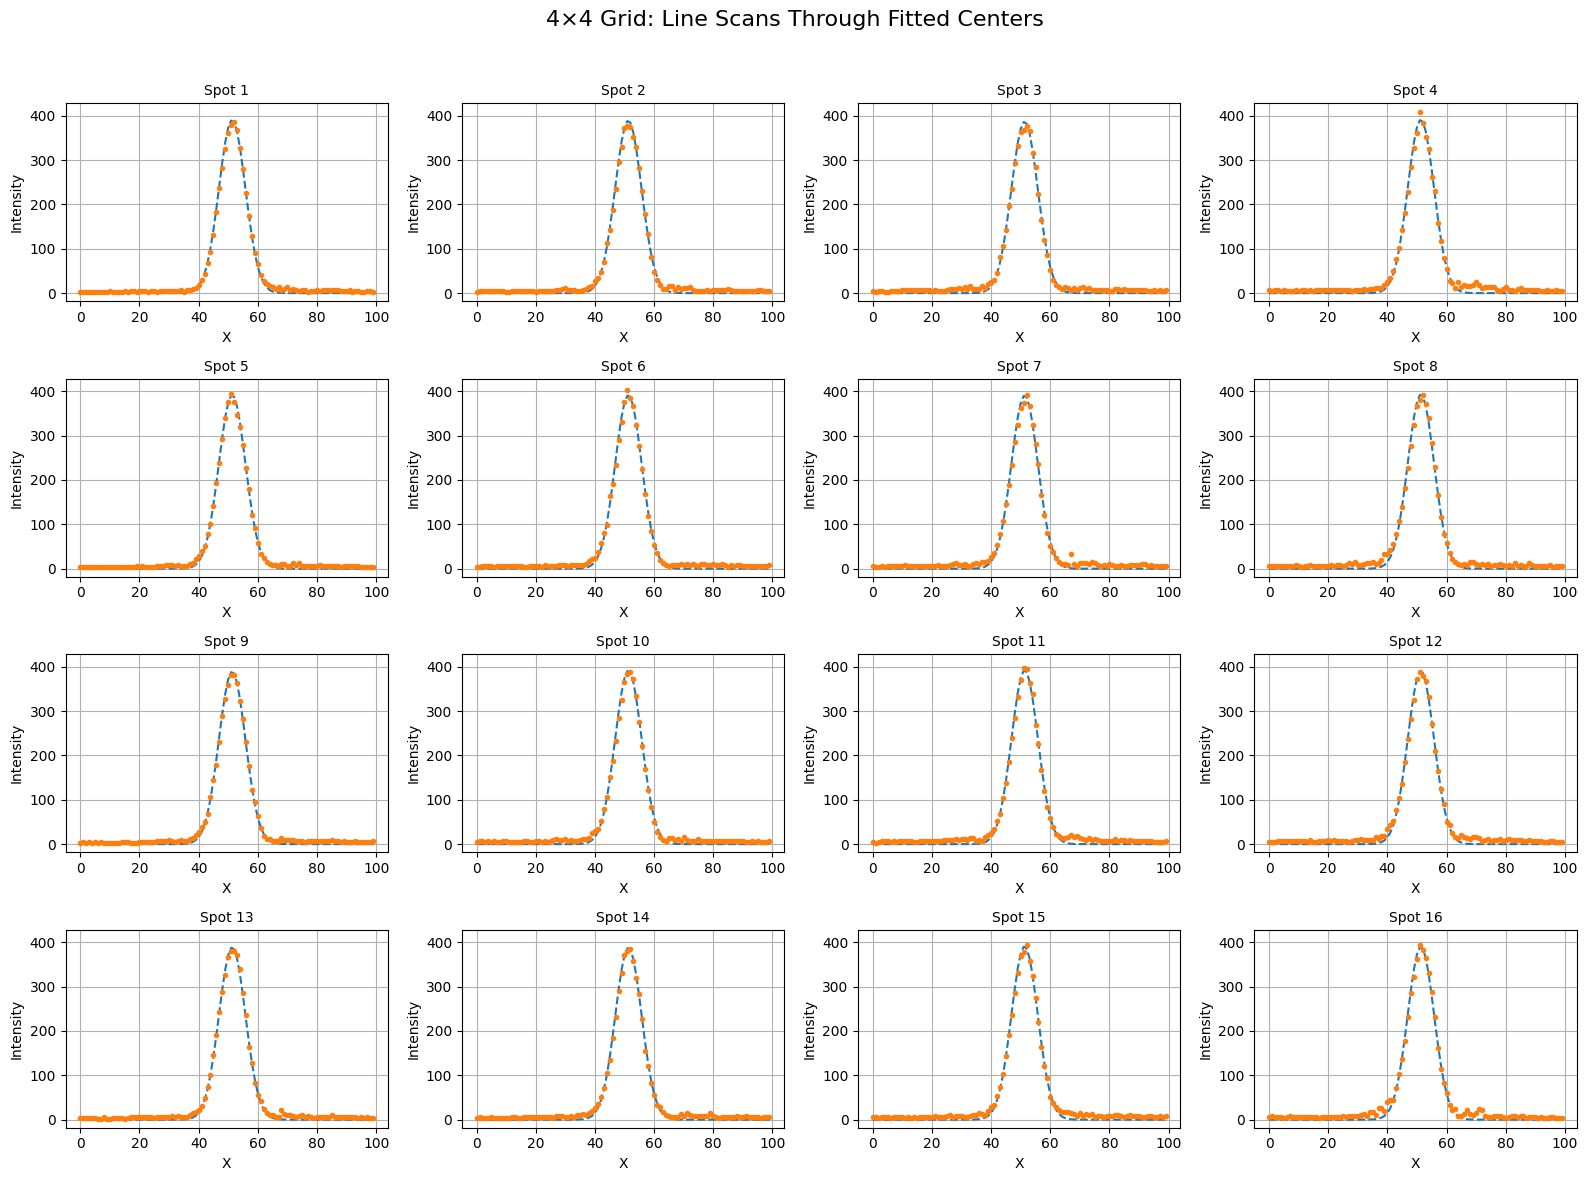

In [102]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import map_coordinates

fig, axs = plt.subplots(4, 4, figsize=(16, 12))
axs = axs.flatten()

all_lines = []

# First pass: gather all line scans for global y-limits
for idx, spot_location in enumerate(spot_locations.T):
    target = img[spot_location[1]-30:spot_location[1]+70, spot_location[0]-40:spot_location[0]+60].T
    result = results[idx]
    cx, cy = result['centerx'], result['centery']
    x_coords = np.arange(target.shape[1])
    y_coords = np.full_like(x_coords, cy)
    line_scan = map_coordinates(target, [y_coords, x_coords], order=1)
    all_lines.append(line_scan)

# Compute global y-limits for consistent scaling
all_lines_stack = np.vstack(all_lines)
ymin, ymax = all_lines_stack.min(), all_lines_stack.max()
pad = 0.05 * (ymax - ymin)
ymin -= pad
ymax += pad

# Second pass: plot
for idx, spot_location in enumerate(spot_locations.T):
    target = img[spot_location[1]-30:spot_location[1]+70, spot_location[0]-40:spot_location[0]+60].T
    result = results[idx]

    cx, cy = result['centerx'], result['centery']
    sigx, sigy = result['sigmax'], result['sigmay']
    A = result['amplitude']
    offset = result.get('offset', 0.0)

    x_coords = np.arange(target.shape[1])
    y_coords = np.full_like(x_coords, cy)
    line_scan = map_coordinates(target, [y_coords, x_coords], order=1)
    fitted_line = A / (2 * np.pi * sigx * sigy) * np.exp(-((x_coords - cx)**2) / (2 * sigx**2)) + offset

    ax = axs[idx]
    ax.plot(x_coords, fitted_line, '--', label='Fit', linewidth=1.5)
    ax.plot(x_coords, line_scan, 'o', label='Data', markersize=3)  # dots only
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"Spot {idx+1}", fontsize=10)
    ax.set_xlabel("X")
    ax.set_ylabel("Intensity")
    ax.grid(True)

plt.suptitle("4×4 Grid: Line Scans Through Fitted Centers", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [105]:
variation_list = [
    [12.1357307, 3.21983959, 3.17136893, 5.08882661, 5.1969195],
    [10.83186892, 2.5798978, 1.59439855, 1.19638911, 1.94596897],
    [5.66542269, 2.28508287, 1.21914854, 0.30211417, 0.75686371],
    [3.45000533, 2.07956254, 0.97813991, 0.12747785, 0.35523899],
    [2.33963809, 1.79056058, 0.92698218, 0.06336408, 0.15563013],
    [1.62160757, 1.61230902, 0.94929711, 0.05145033, 0.10377346],
    [1.44851109, 1.30175943, 0.77499002, 0.04602762, 0.11181651],
    [1.13148255, 1.13569353, 0.7007014, 0.06097444, 0.08036961],
    [0.95845444, 0.9545732, 0.6540371, 0.03317177, 0.06973805],
    [1.12592485, 0.81523896, 0.62917567, 0.03074809, 0.03959714],
    [0.93718541, 0.58268173, 0.53823812, 0.05645414, 0.05258516],
    [0.53243323, 0.8222447, 0.55534303, 0.06347691, 0.06100145],
    [1.01590898, 0.54766539, 0.57283842, 0.05155221, 0.07704107],
    [0.91323908, 0.5412988, 0.39418813, 0.06234254, 0.04418163],
    [0.9513027, 0.46048136, 0.36887675, 0.06477128, 0.0647822],
    [0.54042164, 0.41043056, 0.31878039, 0.077261, 0.02043112],
    [0.56889895, 0.51720025, 0.41557156, 0.0465424, 0.02301819],
    [0.42083402, 0.48116407, 0.40681368, 0.0488031, 0.02073754],
    [0.53435431, 0.4929285, 0.38662281, 0.02550836, 0.03250992],
    [0.41970022, 0.43149918, 0.31483489, 0.03905257, 0.09480559],
    [0.80350842, 0.25402842, 0.31062205, 0.05266667, 0.04398533],
    [0.65934635, 0.44537785, 0.26760948, 0.04920539, 0.06563277],
    [0.51978683, 0.35945032, 0.38902989, 0.08570194, 0.03598581],
    [0.50445393, 0.26559154, 0.21760923, 0.04240757, 0.05765521],
    [0.57241323, 0.24784702, 0.21717251, 0.02592147, 0.02096789],
    [0.29156063, 0.24375364, 0.24316964, 0.02166615, 0.0148525],
    [0.35500691, 0.26690451, 0.28030442, 0.02422709, 0.02882221],
    [0.36519135, 0.31728176, 0.26764124, 0.04590133, 0.04439744],
    [0.43987344, 0.32776546, 0.15921723, 0.08227203, 0.05683697],
    [0.45323332, 0.29473795, 0.25258952, 0.05921101, 0.05624332],
    [0.48119283, 0.19458418, 0.2208815, 0.0444558, 0.03665988],
    [0.46331156, 0.20289462, 0.23398841, 0.0341861, 0.01600587],
    [0.40487635, 0.19764155, 0.26235645, 0.03886183, 0.04583219],
    [0.57938999, 0.2133975, 0.25863261, 0.08745186, 0.04967481],
    [0.65263323, 0.17655668, 0.28299459, 0.08411594, 0.06109279],
    [0.638879, 0.27667689, 0.34459012, 0.03880961, 0.09578485],
    [0.54256798, 0.25565956, 0.19532144, 0.02875977, 0.03841023],
    [0.83186114, 0.35431255, 0.27075194, 0.05736588, 0.0283061],
    [0.93642677, 0.31191913, 0.36738327, 0.06598109, 0.03204145],
    [0.72482978, 0.25133607, 0.20941827, 0.04797245, 0.07722818],
    [0.60384883, 0.18202743, 0.25035347, 0.04967224, 0.07295459],
    [0.59687843, 0.24007959, 0.22885912, 0.03469093, 0.03695939],
    [0.47970909, 0.20884197, 0.19671088, 0.02785115, 0.05480344],
    [0.46031661, 0.15426605, 0.15860636, 0.01923858, 0.10470002],
    [0.4966228, 0.14533037, 0.30054675, 0.02646665, 0.09254084],
    [0.4122863, 0.22805136, 0.21839517, 0.02038832, 0.01878376],
    [0.34708639, 0.20777265, 0.20571533, 0.02930889, 0.02091501],
    [0.49021296, 0.22983633, 0.39148135, 0.04168405, 0.0834241],
    [0.79880156, 0.32518827, 0.24014116, 0.0582259, 0.13527785],
    [0.47757399, 0.2631972, 0.27455128, 0.05124691, 0.03194697],
    [0.37844525, 0.38626407, 0.21326813, 0.05643021, 0.03745115],
    [0.56876467, 0.19155596, 0.18476129, 0.03797484, 0.03639142],
    [0.5651969, 0.21429182, 0.1847077, 0.02902344, 0.05451828],
    [0.4796663, 0.26657696, 0.14253593, 0.02603864, 0.04508101],
    [0.41650376, 0.15406196, 0.213432, 0.04360915, 0.02152896],
    [0.40017286, 0.25646618, 0.19998834, 0.03341872, 0.02894182],
    [0.57149358, 0.31956739, 0.25805102, 0.02648389, 0.02910363],
    [0.84546292, 0.35370883, 0.38350206, 0.06316755, 0.07778841],
    [0.6984922, 0.25979692, 0.19854963, 0.0631086, 0.02938633],
    [0.44835287, 0.33307175, 0.17003577, 0.02960662, 0.06368471],
    [0.45066904, 0.26401177, 0.18066102, 0.04382133, 0.05613234],
    [0.53439419, 0.13604959, 0.19110544, 0.05513292, 0.04722173],
    [0.39649856, 0.19898375, 0.20572748, 0.04182674, 0.03025237],
    [0.54968739, 0.22884893, 0.2191647, 0.03940042, 0.01842827],
    [0.60732711, 0.26442894, 0.32278031, 0.04454722, 0.02274791],
    [0.37621369, 0.11253614, 0.12647546, 0.02021802, 0.02806909],
    [0.30751838, 0.19736843, 0.21389499, 0.02678614, 0.03219579],
    [0.48387516, 0.30820353, 0.22361304, 0.04421671, 0.05976957],
    [0.61814553, 0.25202243, 0.3016196, 0.04975895, 0.0667326],
    [0.44293625, 0.28620814, 0.26286452, 0.05350968, 0.04627642],
    [0.66898875, 0.21107343, 0.31961291, 0.0497815, 0.08388046],
    [0.59685202, 0.31420712, 0.32411364, 0.05977034, 0.03374385],
    [0.64907792, 0.2267226, 0.25517204, 0.04970431, 0.05575003],
    [0.34162776, 0.17685369, 0.24135332, 0.06393093, 0.05467928],
    [0.61835275, 0.50200281, 0.3009459, 0.05657422, 0.04785257],
    [0.86721888, 0.37319584, 0.25032103, 0.04497092, 0.10033257],
    [0.41721339, 0.19363876, 0.23503711, 0.07956622, 0.03199253],
    [0.43636976, 0.19813319, 0.173953, 0.07517371, 0.0329373],
    [0.43593594, 0.2652475, 0.13558547, 0.03279582, 0.09016529],
    [0.46389113, 0.28381176, 0.22581595, 0.06078758, 0.07409106],
    [0.572352, 0.26092572, 0.26313906, 0.09989346, 0.13582879],
    [0.5759644, 0.20335289, 0.16510353, 0.03714739, 0.03024226],
    [0.41721993, 0.15533166, 0.1864775, 0.06974303, 0.166271],
    [0.46454295, 0.27754866, 0.20556889, 0.04584559, 0.12488096],
    [0.41255632, 0.22620131, 0.24380021, 0.03277806, 0.07351801],
    [0.58631793, 0.33892306, 0.25505032, 0.11723867, 0.05196925],
    [0.61798942, 0.32385022, 0.31202367, 0.06785341, 0.05441304],
    [0.4859024, 0.26866988, 0.14150079, 0.06573346, 0.09583477],
    [0.50445977, 0.24166859, 0.32331638, 0.08570235, 0.06111707],
    [0.72347779, 0.20871013, 0.25206017, 0.03351574, 0.04383751],
    [0.65040377, 0.26517505, 0.22463908, 0.03917155, 0.0662426],
    [0.67688399, 0.19385221, 0.19453785, 0.05094586, 0.04004542],
    [0.69886134, 0.26739304, 0.20333558, 0.04633817, 0.02722956],
    [0.54795739, 0.23689393, 0.19541599, 0.03374106, 0.02529957],
    [0.47702168, 0.20514839, 0.24778637, 0.05103547, 0.02102577],
    [0.52813542, 0.16960795, 0.217037, 0.07282605, 0.05049625],
    [0.48391299, 0.21815473, 0.13966013, 0.03389094, 0.02405398],
    [0.4265457, 0.22558281, 0.21801199, 0.04148728, 0.10221906],
    [0.48039725, 0.22382647, 0.22995378, 0.13287778, 0.16467103],
    [0.6789599, 0.29654265, 0.29037306, 0.12849615, 0.11392239]
]

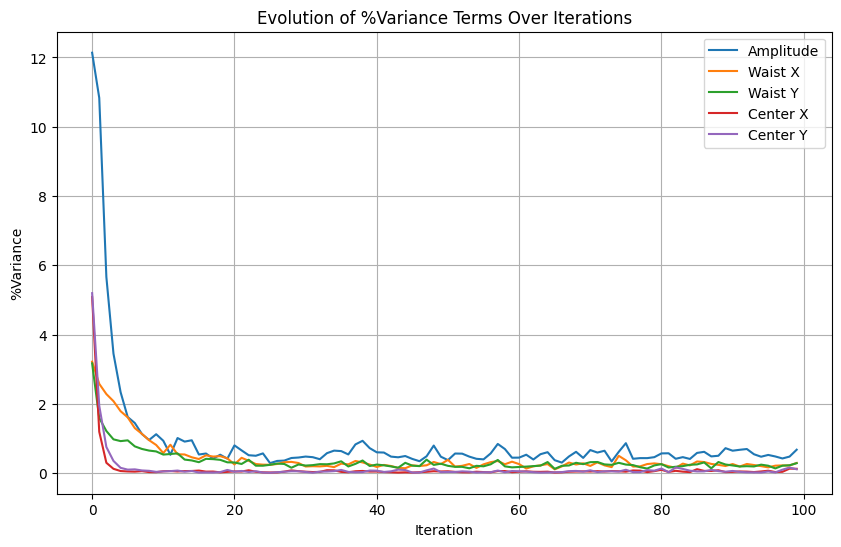

In [137]:
import numpy as np
import matplotlib.pyplot as plt

# Your 2D data
variation_array = np.array(variation_list)  # (iterations x 5)

# Names for the five terms
terms = ['Amplitude', 'Waist X', 'Waist Y', 'Center X', 'Center Y']

# Plotting
plt.figure(figsize=(10, 6))

for i in range(5):
    plt.plot(variation_array[:, i], label=terms[i])

plt.xlabel('Iteration')
plt.ylabel('%Variance')
plt.title('Evolution of %Variance Terms Over Iterations')
plt.legend()
plt.grid(True)
plt.show()